# TweetEval – Offensive Language Detection
## Notebook 06 · Evaluation, model selection and final test

Notebook 05 trained the five required models (Logistic Regression, SVM, Random Forest, Naive Bayes, KNN) and the optional ones
(Complement NB, SGD, Voting, BiLSTM, BERT) and exported their **validation** predictions. This notebook does **not** retrain anything for the comparison. It:

1. loads the validation predictions of every model that ran in notebook 05;
2. computes **accuracy, precision, recall, F1** (offensive = positive class) and shows one **confusion matrix** per model;
3. **compares** the models and **selects the best one** (criterion: F1 of the offensive class on validation);
4. runs the **final test**: the **best model on validation** (BERT if it wins) is scored **once** on the test set; the best classical model is retrained on train + validation and scored too, as a baseline;
5. **saves** the model, the metrics, the predictions and the figures.

> The test set is never used to choose anything: the winner is picked on validation, then scored once in section 5 (alongside the best classical baseline).

## 1. Setup and loading the results of notebook 05

In [14]:
import sys, re, ast, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src.utils import setup_paths, savefig
from src.features import fit_tfidf, transform_tfidf
from src.evaluation import compute_metrics, get_confusion_matrix
from src import logistic_regression, svm, random_forest, naive_bayes, knn, extra_models

P = setup_paths("06_evaluation")
M05 = P.root / "results" / "metrics" / "05_model_training"
PRED05 = P.root / "results" / "predictions" / "05_model_training"
PRED06 = P.root / "results" / "predictions" / "06_evaluation"
MODEL_DIR = P.root / "models"
for d in (P.figures, P.metrics, PRED06, MODEL_DIR):
    Path(d).mkdir(parents=True, exist_ok=True)

slug = lambda s: re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")
SEED = config.RANDOM_STATE
for f in ("models_validation_metrics.csv", "best_hyperparameters.csv"):
    assert (M05 / f).exists(), f"{f} not found: run notebook 05 first."

hp = pd.read_csv(M05 / "best_hyperparameters.csv")                    # Model, Group, params (as text)
hp["params"] = hp["params"].apply(lambda s: ast.literal_eval(s) if s != "None" else {})
PARAMS = dict(zip(hp["Model"], hp["params"]))
GROUP = dict(zip(hp["Model"], hp["Group"]))

val = pd.read_csv(P.processed / "val_final.csv", keep_default_na=False)
y_val = val["label"].to_numpy()

VAL_PRED, VAL_SCORE = {}, {}
for name in hp["Model"]:
    f = PRED05 / f"val_predictions_{slug(name)}.csv"
    if f.exists():
        d = pd.read_csv(f, keep_default_na=False)
        assert (d["y_true"].to_numpy() == y_val).all(), f"{name}: predictions do not match val_final.csv"
        VAL_PRED[name] = d["y_pred"].to_numpy()
        VAL_SCORE[name] = d["score_offensive"].to_numpy() if "score_offensive" in d else None
print(f"{len(VAL_PRED)} models loaded:", list(VAL_PRED))

10 models loaded: ['Logistic Regression', 'SVM (LinearSVC)', 'Random Forest', 'Naive Bayes', 'KNN', 'Complement NB', 'SGD (modified Huber)', 'Voting ensemble', 'BiLSTM', 'BERT']


## 2. Metrics per model (validation set)
Recomputed from the saved predictions with the project's shared `compute_metrics`, so every model is scored by the same code.
**Offensive = positive class.** F1 is the main criterion because accuracy is inflated by the majority class (about 2 tweets in 3 are non-offensive).

In [15]:
rows = []
for name, pred in VAL_PRED.items():
    m = compute_metrics(y_val, pred)
    rows.append({"Model": name, "Group": GROUP[name], "Accuracy": m["accuracy"], "Precision": m["precision"],
                 "Recall": m["recall"], "F1": m["f1"]})
results = pd.DataFrame(rows).round(4).sort_values("F1", ascending=False).reset_index(drop=True)
display(results)

,Model,Group,Accuracy,Precision,Recall,F1
0,BERT,optional,0.7983,0.6765,0.8017,0.7338
1,BiLSTM,optional,0.7107,0.5651,0.7190,0.6328
2,Random Forest,required,0.7719,0.7163,0.5664,0.6326
3,Logistic Regression,required,0.7402,0.6247,0.6275,0.6261
4,Voting ensemble,optional,0.7424,0.6305,0.6209,0.6257
5,SGD (modified Huber),optional,0.7409,0.6278,0.6209,0.6243
6,SVM (LinearSVC),required,0.7417,0.6303,0.6166,0.6233
7,Naive Bayes,required,0.7047,0.5749,0.5686,0.5717
8,Complement NB,optional,0.7047,0.5749,0.5686,0.5717
9,KNN,required,0.6654,0.5185,0.4880,0.5028


## 3. Confusion matrices
Bottom-left = offensive tweets **missed** (false negatives); top-right = non-offensive tweets **wrongly flagged** (false positives).

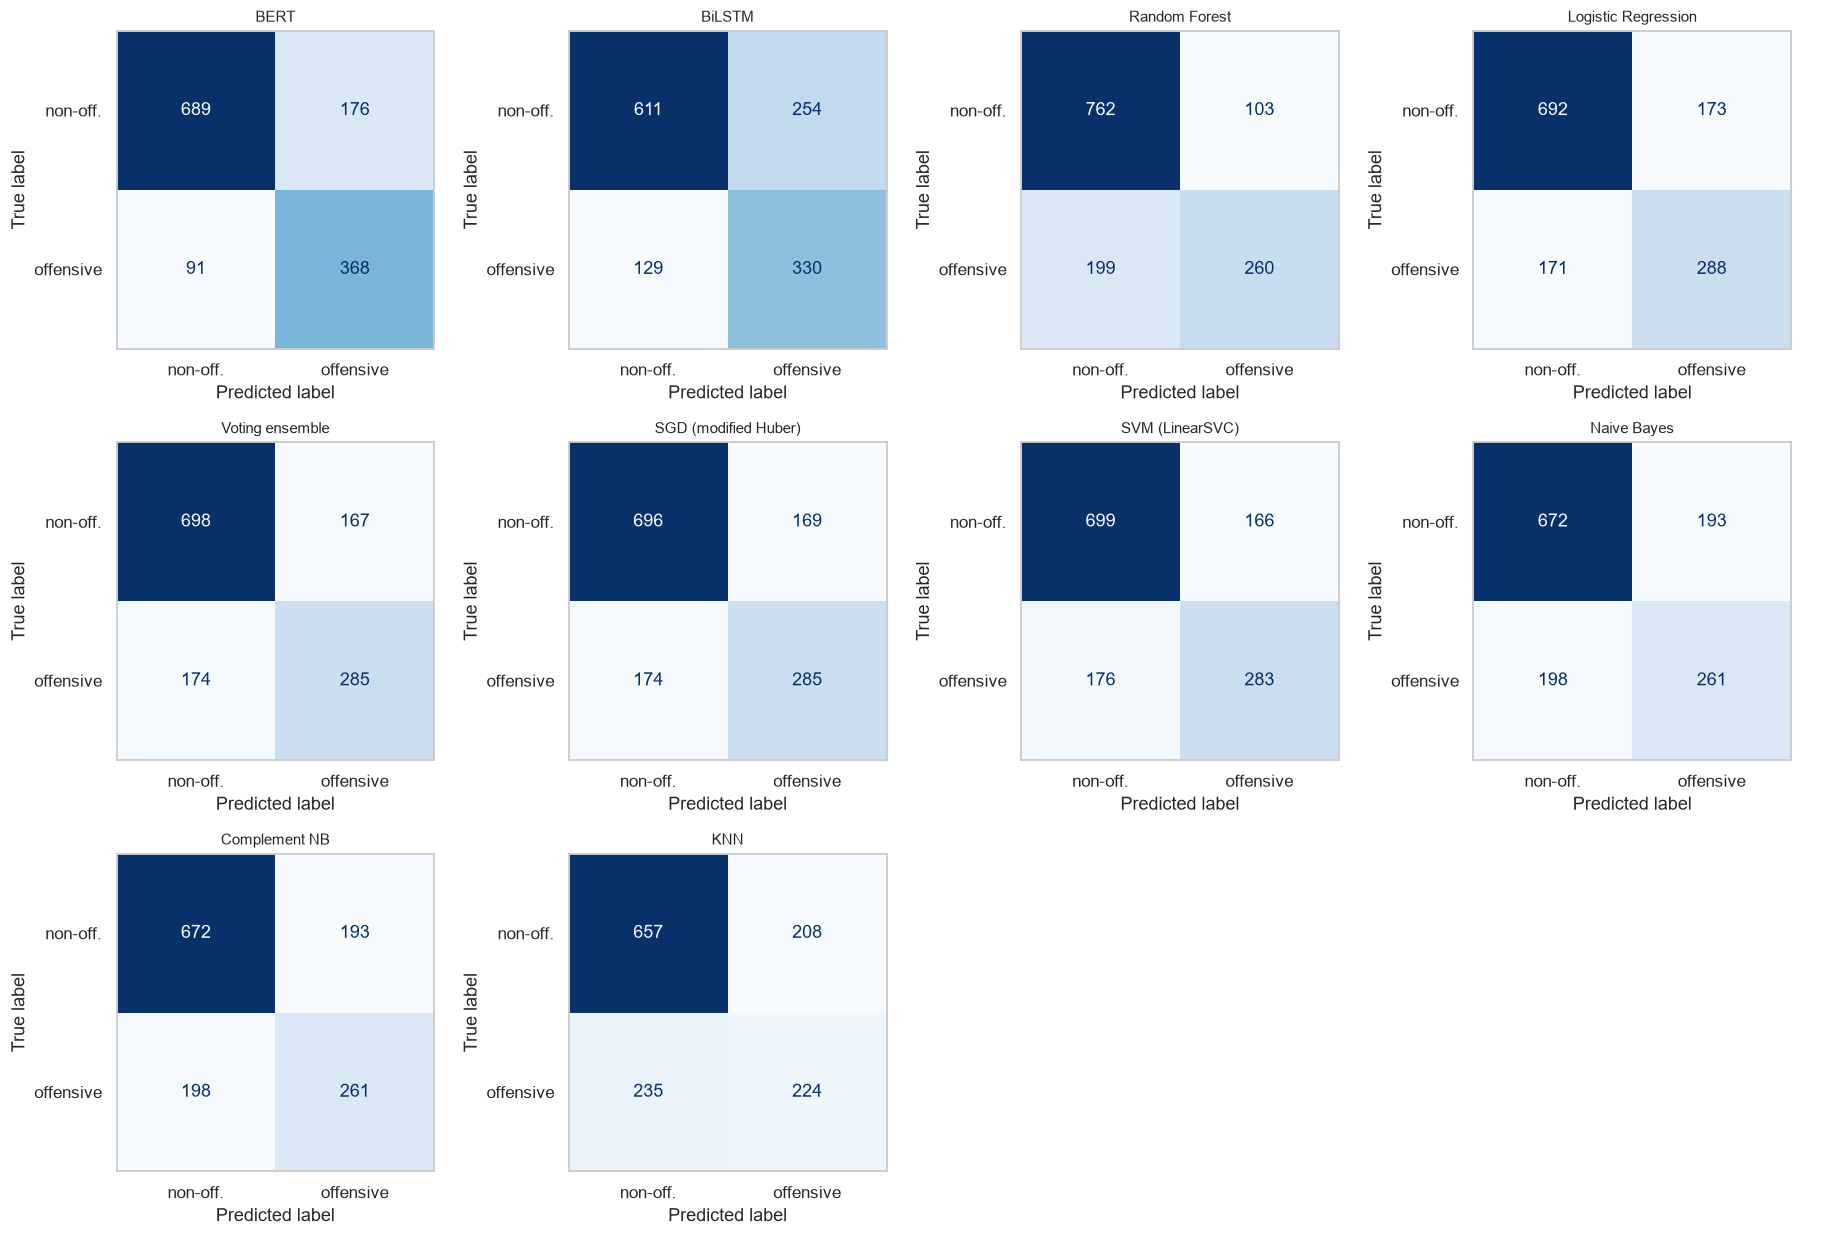

In [16]:
n = len(VAL_PRED); cols = 4; nrows = int(np.ceil(n / cols))
fig, axes = plt.subplots(nrows, cols, figsize=(4.2 * cols, 3.8 * nrows))
for ax, name in zip(np.ravel(axes), results["Model"]):
    ConfusionMatrixDisplay(get_confusion_matrix(y_val, VAL_PRED[name]),
                           display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10); ax.grid(False)
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
fig.tight_layout(); savefig(fig, P.figures / "confusion_matrices_validation.png"); plt.show()

## 4. Comparison and selection of the best model

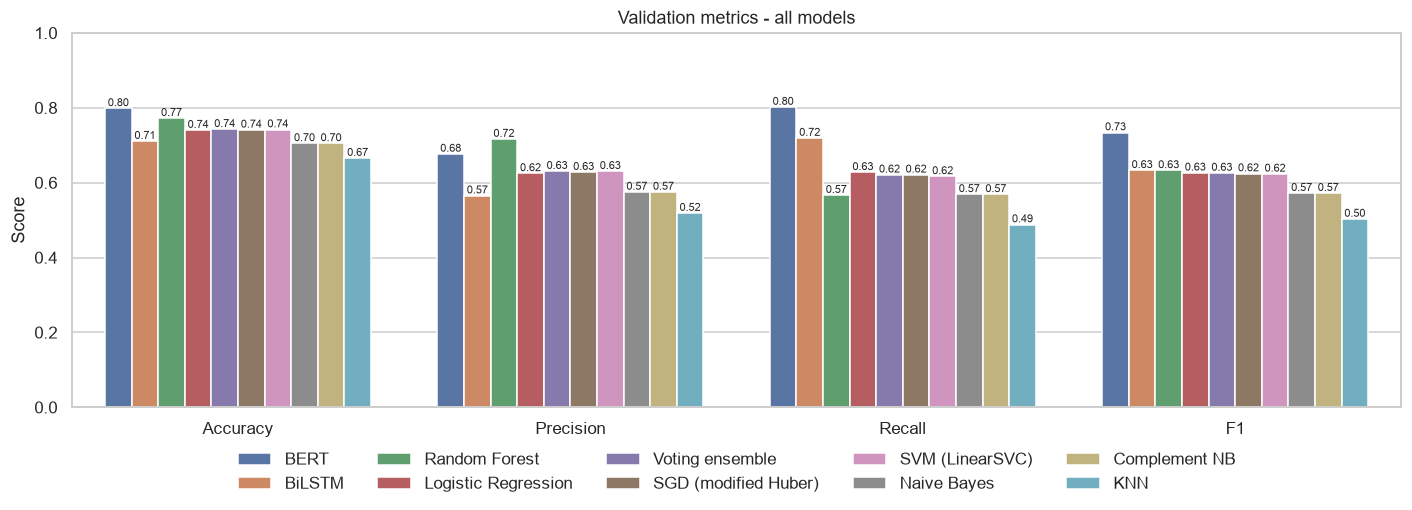

Best on validation : BERT  (F1 = 0.7338, P = 0.6765, R = 0.8017)

Overall winner (validation) : BERT
Best classical baseline     : Random Forest  with {'max_depth': None, 'n_estimators': 300}


In [17]:
long = results.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"], var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.barplot(data=long, x="Metric", y="Score", hue="Model", hue_order=list(results["Model"]), ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_title("Validation metrics - all models")
ax.legend(title="", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout(); savefig(fig, P.figures / "comparison_validation.png"); plt.show()

best = results.iloc[0]
tied = results[results["F1"] >= best["F1"] - 0.005]["Model"].tolist()
print(f"Best on validation : {best['Model']}  (F1 = {best['F1']:.4f}, P = {best['Precision']:.4f}, R = {best['Recall']:.4f})")
if len(tied) > 1:
    print("Within 0.005 F1 (statistically tied on 1,324 tweets):", tied)
    print("-> prefer the simplest / fastest of these if you want to justify a different choice (see CV table of notebook 05).")

# Two models go to the test set:
#  - SELECTED           = overall winner on validation (the model we report; may be BERT / BiLSTM)
#  - SELECTED_CLASSICAL = best scikit-learn model, refitted on train + validation (baseline for comparison)
CLASSICAL = ["Logistic Regression", "SVM (LinearSVC)", "Random Forest", "Naive Bayes", "KNN",
             "Complement NB", "SGD (modified Huber)", "Voting ensemble"]
eligible = results[results["Model"].isin(CLASSICAL)]
SELECTED_CLASSICAL = eligible.iloc[0]["Model"]
SELECTED = best["Model"]
print(f"\nOverall winner (validation) : {SELECTED}")
print(f"Best classical baseline     : {SELECTED_CLASSICAL}  with {PARAMS[SELECTED_CLASSICAL]}")

**Reading.** Differences of about one F1 point are within the noise of a single validation split. The choice should be justified with F1, the
precision/recall balance (for moderation, missing offensive tweets is usually worse than a few false alarms) and the simplicity of the model.
The overall winner is chosen by validation F1 alone. The restriction to classical models only applies to the **refit on train + validation**, which is not possible for neural models; it is not a quality criterion.


## 5. Final test and saving
The best **classical** model is **refitted on train + validation** (TF-IDF included, still no test data) with the hyperparameters chosen in notebook 05, then
scored **once** on the test set: it is the baseline. The overall winner (BERT or BiLSTM when it wins) is scored right after, in the next section.

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.8047,0.7,0.525,0.6


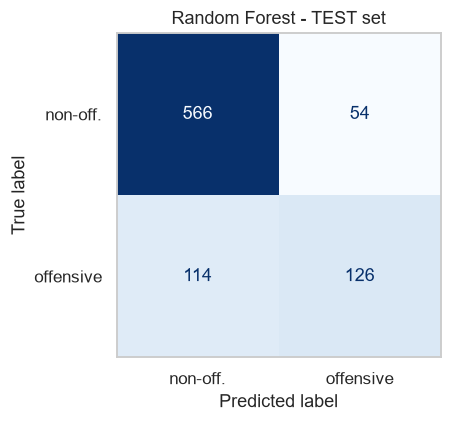

Validation F1 = 0.6326  ->  Test F1 = 0.6000  (a small drop is normal: hyperparameters were tuned on validation)


In [18]:
test_path = P.processed / "test_final.csv"
assert test_path.exists(), "test_final.csv not found: run notebook 03 first."
train = pd.read_csv(P.processed / "train_final.csv", keep_default_na=False)
test  = pd.read_csv(test_path, keep_default_na=False)
full  = pd.concat([train, val], ignore_index=True)

vec, X_full = fit_tfidf(full["text_clean"])                       # vocabulary + IDF from train + val only
X_test = transform_tfidf(vec, test["text_clean"])
y_full, y_test = full["label"].to_numpy(), test["label"].to_numpy()

def build_final(name, X, y):
    p = PARAMS[name]
    if name == "Logistic Regression": return logistic_regression.train(X, y, **p)
    if name == "SVM (LinearSVC)":     return svm.train(X, y, **p)
    if name == "Random Forest":       return random_forest.train(X, y, **p)
    if name == "Naive Bayes":         return naive_bayes.train(X, y, **p)
    if name == "KNN":                 return knn.train(X, y, **p)
    if name == "Complement NB":       return extra_models.train_complement_nb(X, y, **p)
    if name == "SGD (modified Huber)":return extra_models.train_sgd(X, y, **p)
    if name == "Voting ensemble":
        return extra_models.train_voting(X, y, PARAMS["Logistic Regression"]["C"],
                                         PARAMS["SVM (LinearSVC)"]["C"], PARAMS["Naive Bayes"]["alpha"])
    raise ValueError(name)

final_model = build_final(SELECTED_CLASSICAL, X_full, y_full)
y_pred_test = final_model.predict(X_test)
mt = compute_metrics(y_test, y_pred_test)
test_table = pd.DataFrame([{"Model": SELECTED_CLASSICAL, "Accuracy": mt["accuracy"], "Precision": mt["precision"],
                            "Recall": mt["recall"], "F1": mt["f1"]}]).round(4)
display(test_table)

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(get_confusion_matrix(y_test, y_pred_test),
                       display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{SELECTED_CLASSICAL} - TEST set"); ax.grid(False)
fig.tight_layout(); savefig(fig, P.figures / "confusion_matrix_test.png"); plt.show()

v = results[results["Model"] == SELECTED_CLASSICAL].iloc[0]
print(f"Validation F1 = {v['F1']:.4f}  ->  Test F1 = {mt['f1']:.4f}  (a small drop is normal: hyperparameters were tuned on validation)")

In [19]:
# ---- saving ------------------------------------------------------------------------
joblib.dump({"vectorizer": vec, "model": final_model, "name": SELECTED_CLASSICAL, "params": PARAMS[SELECTED_CLASSICAL]},
            MODEL_DIR / "best_model.joblib")                       # load later: bundle = joblib.load(...)
results.to_csv(P.metrics / "validation_comparison.csv", index=False)
test_table.to_csv(P.metrics / "final_test_metrics.csv", index=False)
pd.DataFrame({"text": test["text"] if "text" in test else test["text_clean"],
              "y_true": y_test, "y_pred": y_pred_test}).to_csv(PRED06 / "test_predictions_best_model.csv", index=False)
print("Saved:")
for p in (MODEL_DIR / "best_model.joblib", P.metrics / "validation_comparison.csv",
          P.metrics / "final_test_metrics.csv", PRED06 / "test_predictions_best_model.csv"):
    print(" -", Path(p).relative_to(P.root))

Saved:
 - models\best_model.joblib
 - results\metrics\06_evaluation\validation_comparison.csv
 - results\metrics\06_evaluation\final_test_metrics.csv
 - results\predictions\06_evaluation\test_predictions_best_model.csv


## 5b. Final test of the overall winner (BERT / BiLSTM when it wins)
Neural models cannot be refitted on train + validation like the scikit-learn ones, so the **best-epoch model trained on the training set only**
(saved by notebook 05) is loaded and scored **once** on the test set. BERT reads the original tweet (`text`), the BiLSTM the cleaned one (`text_clean`).
If the overall winner is a classical model, this cell does nothing: section 5 already covers it.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,Model,Accuracy,Precision,Recall,F1,Role
0,BERT,0.8302,0.6822,0.7333,0.7068,final (best on validation)
1,Random Forest,0.8047,0.7000,0.5250,0.6000,classical baseline


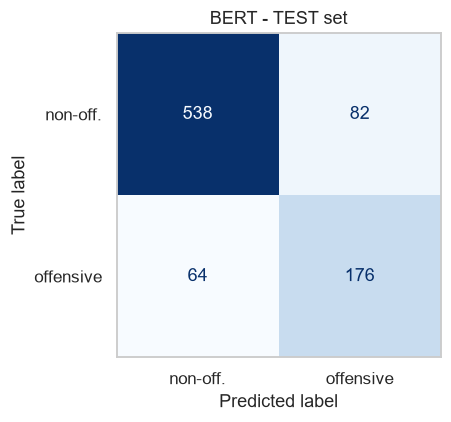

BERT: Validation F1 = 0.7338  ->  Test F1 = 0.7068


In [20]:
from src import bert_model, lstm_model

NEURAL = {   # model name in `results` : (loader, predictor, text column fed to the model)
    "BiLSTM": (lambda: lstm_model.load_lstm(MODEL_DIR / "bilstm.pt"), lstm_model.predict_lstm, "text_clean"),
    "BERT":   (lambda: bert_model.load_bert(MODEL_DIR / "bert"),       bert_model.predict_bert, "text"),
}

if SELECTED in NEURAL:
    load, predict, col = NEURAL[SELECTED]
    saved = MODEL_DIR / ("bilstm.pt" if SELECTED == "BiLSTM" else "bert")
    assert saved.exists(), f"{saved} not found: add the save_* call after the {SELECTED} training cell in notebook 05 and rerun it."
    res_nn = load()
    scores_test = predict(res_nn, test[col])                 # probability of "offensive"
    y_pred_nn = (scores_test >= 0.5).astype(int)             # same 0.5 threshold as on validation
    mt_nn = compute_metrics(y_test, y_pred_nn)
    nn_table = pd.DataFrame([{"Model": SELECTED, "Accuracy": mt_nn["accuracy"], "Precision": mt_nn["precision"],
                              "Recall": mt_nn["recall"], "F1": mt_nn["f1"]}]).round(4)
    display(pd.concat([nn_table.assign(Role="final (best on validation)"),
                       test_table.assign(Role="classical baseline")], ignore_index=True))

    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(get_confusion_matrix(y_test, y_pred_nn),
                           display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{SELECTED} - TEST set"); ax.grid(False)
    fig.tight_layout(); savefig(fig, P.figures / f"confusion_matrix_test_{slug(SELECTED)}.png"); plt.show()

    nn_table.to_csv(P.metrics / "final_test_metrics_neural.csv", index=False)
    pd.DataFrame({"text": test["text"], "y_true": y_test, "y_pred": y_pred_nn, "score_offensive": scores_test}
                 ).to_csv(PRED06 / f"test_predictions_{slug(SELECTED)}.csv", index=False)
    v_nn = results[results["Model"] == SELECTED].iloc[0]
    print(f"{SELECTED}: Validation F1 = {v_nn['F1']:.4f}  ->  Test F1 = {mt_nn['f1']:.4f}")
else:
    print(f"The overall winner ({SELECTED}) is a classical model: the test result of section 5 is the final one.")


**Reading.** `best_model.joblib` contains the TF-IDF vectorizer **and** the classifier: to predict on a new tweet, clean it like `text_clean`,
call `bundle["vectorizer"].transform([...])` then `bundle["model"].predict(...)`.
`best_model.joblib` is the best **classical** pipeline (baseline). The neural winner is stored by notebook 05 in `models/bert/` or `models/bilstm.pt`.
